# Experiment 1 · Single-target trials from the trained start

**Date:** 2026-11-07 · **Agent:** `baseline_s1` · **Status:** observation (1 seed, 10 trials)

## Question
How does the trained baseline agent actually move the mass on the simplest possible trial,
one target, starting from the trained start position x = 0? What do the position, velocity
and force traces look like, and what does the reaction time (RT) measure on these trials?

## Design
- 10 trials, each with **one target**, preview H = 1. The target position is drawn from the
  task distribution (|T| ≤ 0.9, at least 0.15 from the start).
- The **go cue is random**, drawn from the task distribution (hold of 0.25–1.0 s).
- Start at x = 0, as in training.
- Noiseless plant and mean action (the same settings every probe in `analyze.py` uses), so
  the traces show the policy itself, not noise.
- RT is defined as in `metrics.segment_kinematics`: from the go cue to the first step at
  which |v| reaches 5% of that reach's peak speed. Steps are 20 ms.
- Movement time (MT): from movement onset to first entry into the target.

In [1]:
from exp_tools import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Video, display
from single_target_video import make_video, outcome

use_style()
pd.set_option("display.precision", 3)

## Run the trials and render the video

The video plays the 10 trials back to back in real time. Panels: the track, position, velocity, and force (the policy's command *u* and the actuator force *a*, which lags *u* by 50 ms).

In [2]:
out, traj, infos = make_video(RUNS / "baseline_s1", trials=10, seed=0, fmt="mp4",
                              name="exp01_single_target")
print(f"video: {out}")
display(Video(rel(out), embed=False, width=820))

video: /Users/aghavamp/Desktop/Projects/SeqHorizon_basic/1D/runs/baseline_s1/videos/exp01_single_target.mp4


In [3]:
tbl = pd.DataFrame([{
    "trial": i + 1, "target": d["target"], "hold_ms": d["hold_ms"], "RT_ms": d["rt_ms"],
    "MT_ms": d["mt_ms"], "peak_v": d["peak"], "outcome": outcome(d)} for i, d in enumerate(infos)])
tbl

,trial,target,hold_ms,RT_ms,MT_ms,peak_v,outcome
0,1,0.776,580.0,20.0,540.0,2.156,ok
1,2,-0.827,720.0,0.0,740.0,-1.847,ok
2,3,0.418,520.0,20.0,360.0,1.515,ok
3,4,0.206,300.0,20.0,220.0,0.965,ok
4,5,-0.849,660.0,0.0,740.0,-1.883,ok
5,6,0.395,420.0,20.0,340.0,1.474,ok
6,7,-0.871,700.0,0.0,760.0,-1.914,ok
7,8,0.464,260.0,0.0,400.0,1.630,ok
8,9,-0.781,900.0,0.0,700.0,-1.774,ok
9,10,0.772,960.0,20.0,540.0,2.133,ok


## The traces, aligned to the go cue

All 10 trials on one figure, with time measured from the go cue. Position is shown as distance travelled towards the target (positive = towards it), so leftward and rightward reaches overlay.

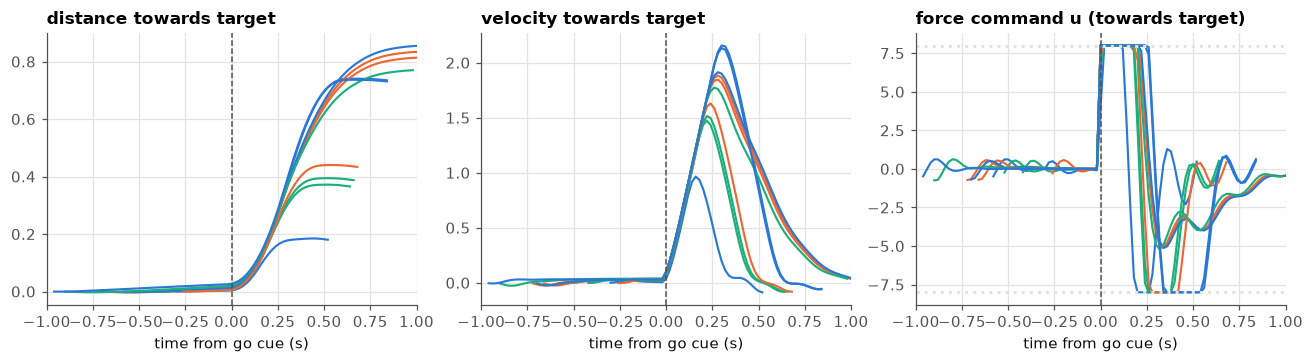

In [4]:
dt = traj["dt"]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for i, d in enumerate(infos):
    g, T = d["go"], d["T"]
    s = np.sign(d["target"] - d["start"])
    t = (np.arange(T) - g) * dt
    axs[0].plot(t, s * (traj["x"][:T, i] - d["start"]), lw=1.4)
    axs[1].plot(t, s * traj["v"][:T, i], lw=1.4)
    axs[2].plot(t, s * traj["u"][:T, i], lw=1.4)
for ax, lab in zip(axs, ["distance towards target", "velocity towards target",
                         "force command u (towards target)"]):
    ax.axvline(0, color=INK_SOFT, ls="--", lw=1)
    ax.set_xlabel("time from go cue (s)")
    ax.set_title(lab)
    ax.set_xlim(-1.0, 1.0)
axs[2].axhline(8, color=GRID, ls=":"); axs[2].axhline(-8, color=GRID, ls=":")
plt.tight_layout(); plt.show()

## What happens around the go cue

The state on the steps just before and after the go cue, for every trial. `thr` is the 5% of peak speed that the RT definition uses. RT is 0 ms when the speed on the go step itself already exceeds `thr`, and 20 ms when it only does so one step later.

In [5]:
rows = []
for i, d in enumerate(infos):
    g, s = d["go"], np.sign(d["target"] - d["start"])
    row = {"trial": i + 1, "RT_ms": d["rt_ms"], "thr (5% peak)": 0.05 * abs(d["peak"])}
    for k in (-1, 0, 1):
        row[f"v[go{k:+d}]"] = s * traj["v"][g + k, i]
    for k in (-1, 0):
        row[f"u[go{k:+d}]"] = s * traj["u"][g + k, i]
    row["x[go-1]-start"] = s * (traj["x"][g - 1, i] - d["start"])
    rows.append(row)
pd.DataFrame(rows)

,trial,RT_ms,thr (5% peak),v[go-1],v[go+0],v[go+1],u[go-1],u[go+0],x[go-1]-start
0,1,20.0,0.108,0.032,0.095,0.198,7.943e-04,8.000,0.014
1,2,0.0,0.092,0.036,0.100,0.202,5.005e-03,8.000,0.012
2,3,20.0,0.076,0.016,0.070,0.167,-2.200e-02,6.851,0.010
3,4,20.0,0.048,0.006,0.037,0.120,-8.805e-02,4.016,0.003
4,5,0.0,0.094,0.036,0.100,0.202,9.902e-03,8.000,0.010
5,6,20.0,0.074,0.017,0.069,0.164,-1.987e-02,6.617,0.008
6,7,0.0,0.096,0.036,0.100,0.202,6.219e-03,8.000,0.012
7,8,0.0,0.082,0.025,0.084,0.183,3.319e-02,7.375,0.005
8,9,0.0,0.089,0.036,0.099,0.201,-3.342e-03,8.000,0.019
9,10,20.0,0.107,0.028,0.092,0.194,-6.838e-03,8.000,0.026


## Conclusion

**The reach.** All 10 trials succeed. On the go step itself the force command jumps towards
its maximum: +8 for the far targets (|T| ≥ 0.77), 4.0–7.4 for nearer ones, so the opening
push scales with distance. Partway through it flips to braking (full −8 on long reaches),
before peak velocity because the actuator force lags the command. Velocity is single-peaked;
peak speed (0.97–2.16) and movement time (220–760 ms) both grow with target distance.

**The hold is not still.** After a small force transient in the first ~0.2 s, the mass drifts
towards the target at a nearly constant speed with almost no force. The drift is faster for
farther targets (v just before go ≈ 0.036 for |T| ≈ 0.8, ≈ 0.016 for |T| ≈ 0.4, ≈ 0.006 for
|T| ≈ 0.2). By the go cue it has moved 0.003–0.026 towards the target, far inside the 0.15
false-start limit.

**RT, as currently defined, does not measure a reaction.** In every trial the policy responds
on the go step itself (there is no sensory delay). Whether RT comes out as 0 or 20 ms depends
only on whether the speed reached on the go step (pre-go drift + one step of force,
0.037–0.100) exceeds 5% of peak speed (0.048–0.108). Far targets have both more drift and a
threshold just below 0.100, so they come out at 0 ms. **So the reported RT mostly reflects
pre-go drift and the 20 ms step, not response latency.** The earlier observation that RT falls
with hold duration should not be interpreted until RT is redefined (for example from the force
command) and re-measured.

*Limits: one seed, 10 trials, noiseless plant.*